# XGBoost

XGBoost (*eXtreme Gradient Boosting*, Chen and Guestrin, 2016) is the library that made [gradient boosting](gradient_boosting.ipynb) the standard model for tables of data: for years it won most machine-learning competitions on tabular data, and it is still what many teams use. The method is the same: small trees, each fitted to what the previous ones got wrong. What XGBoost adds is a sharper version of each step, and the engineering to run it fast on real data. It has its own package, `xgboost`, with classes that follow scikit-learn's conventions, so it fits in the same workflows.

## The raw data

The raw California housing data of [California housing with pipelines](../../basic-workflows/california_with_pipelines.ipynb), with its missing bedrooms and its text column, and the same training, validation and test sets. The text column is turned into pandas' `category` type, which XGBoost can read directly:

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

housing = pd.read_csv("https://github.com/ageron/data/raw/main/housing/housing.csv")
housing["ocean_proximity"] = housing["ocean_proximity"].astype("category")
X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_validation, y_train, y_validation = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
X_train["total_bedrooms"].isna().sum()

np.int64(114)

## A first model

In [ ]:
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

first_model = XGBRegressor(n_estimators=300, learning_rate=0.1, enable_categorical=True, random_state=42)
first_model.fit(X_train, y_train)
mean_absolute_error(y_validation, first_model.predict(X_validation))

30374.675275935682

Without a pipeline, imputation or encoding, the validation error is about \$30,400, already better than the best model of [California housing with pipelines](../../basic-workflows/california_with_pipelines.ipynb) on the same validation rows (the forest, about \$31,600). The missing values and the category went straight in.

## What XGBoost adds

Four things distinguish it from the boosting built by hand in [Gradient boosting](gradient_boosting.ipynb):

- **Steps that use the curvature of the error.** Each tree is fitted using not only the gradient of the error (the direction to move each prediction) but also its second derivative (how quickly that direction changes). With both, the best value of each leaf has a formula, $w = -G / (H + \lambda)$, where $G$ and $H$ add up the gradients and second derivatives of the rows in that leaf. This is Newton's method instead of plain gradient descent (which `HistGradientBoostingRegressor` also uses), and it makes the same procedure work for any error that has two derivatives.
- **A penalty in the objective.** XGBoost minimises the error *plus* a cost for each leaf (`gamma`) and a penalty on the size of the leaf values (`reg_lambda`, the $\lambda$ above, like [Ridge](../../ml-fundamentals/regularization.ipynb); and `reg_alpha`, like Lasso). A split is only made if it reduces the error by more than it costs: the trees are pruned by the objective itself.
- **Missing values with a learned direction.** At each split, the rows with a missing value are tried on both sides, and sent to whichever reduces the error more. The 114 training rows without `total_bedrooms` needed no imputation.
- **Speed.** Histograms of the features (as in `HistGradientBoostingRegressor`), parallel search of the splits, and graphics cards when asked to (`device="cuda"`).

## Early stopping on a validation set

The number of trees is the setting that matters most, and XGBoost finds it with early stopping, as `HistGradientBoostingRegressor` did. Here the held-out rows are given explicitly, with `eval_set`: after each tree, XGBoost measures `eval_metric` on them, and stops when it hasn't improved for `early_stopping_rounds` trees. The model keeps every tree it trained, but `predict` uses only those up to the best one. With several pairs in `eval_set`, the last one is the one watched; the training pair only draws its curve. A high `n_estimators` is only a ceiling; this is the pattern to use with XGBoost:

In [ ]:
model = XGBRegressor(n_estimators=5000, learning_rate=0.05, early_stopping_rounds=50, eval_metric="mae",
                     enable_categorical=True, random_state=42)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_validation, y_validation)], verbose=False)
model.best_iteration + 1, model.best_score

(800, 29839.074310539305)

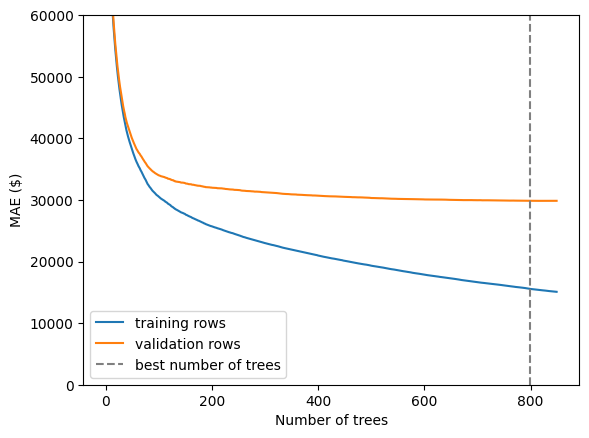

In [ ]:
import matplotlib.pyplot as plt

history = model.evals_result()
plt.plot(history["validation_0"]["mae"], label="training rows")
plt.plot(history["validation_1"]["mae"], label="validation rows")
plt.axvline(model.best_iteration, color="gray", linestyle="--", label="best number of trees")
plt.ylim(0, 60_000)
plt.xlabel("Number of trees")
plt.ylabel("MAE ($)")
plt.legend()
plt.show()

The validation error falls quickly over the first hundred trees and then very slowly, reaching its lowest point after 800 trees, about \$29,800; training stopped 50 trees later, when no improvement had come. The training error keeps falling all the way: the trees go on learning the training rows long after they stop helping with new ones. The gap between the two curves widens with every tree, and early stopping decides when it is no longer worth it.

The validation set has now made a decision, the number of trees, so its error, like any score used to choose, is slightly optimistic ([Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb)). The rows given to `eval_set` must never be the test rows: that would be choosing on the test set, a mistake that is easy to make with this API.

## Testing once

In [ ]:
mean_absolute_error(y_test, model.predict(X_test))

30294.923704635265

About \$30,300 on the test districts, against about \$32,400 for the forest tested in [California housing with pipelines](../../basic-workflows/california_with_pipelines.ipynb) on the same rows: some 6% lower, with less code, since this model needed almost no preparation of the data (only the text column had to be marked as a category), and although it learned from fewer rows: 12,384 against the forest's 16,512, because the rest were kept for early stopping.

## LightGBM and CatBoost

Two other libraries implement the same method, each with its own emphasis. **LightGBM** (Microsoft) grows each tree leaf by leaf, always splitting the leaf that most reduces the error, and is often the fastest on large tables; scikit-learn's `HistGradientBoostingRegressor` was inspired by it. **CatBoost** (Yandex) handles categorical columns with many values particularly well, and its default settings are often good without tuning. On most tables the three reach similar errors once tuned; the choice usually depends on the data's size, its categories, and what the team already uses.

## Settings

| Setting | Meaning | Usual approach |
| --- | --- | --- |
| `n_estimators` | maximum number of trees | high, with `early_stopping_rounds` deciding |
| `learning_rate` | how much of each tree is added | 0.01 to 0.1: smaller needs more trees |
| `max_depth` | depth of each tree (default 6) | 3 to 10 |
| `min_child_weight` | minimum sum of second derivatives in a leaf; for the squared error, the minimum number of rows | larger smooths the model |
| `subsample`, `colsample_bytree` | share of rows, and of features, each tree sees | below 1, to make the trees differ, as the bootstrap samples and the random features of a [random forest](random_forests.ipynb) do (a forest's choice of features at each split is `colsample_bynode`) |
| `reg_lambda`, `reg_alpha`, `gamma` | the penalties of the objective | raise them when the model overfits |
| `eval_metric`, `early_stopping_rounds` | what to watch on `eval_set`, and how patiently | the measure the problem is judged by |

The search for the best combination is the subject of [Cross-validation and hyperparameter search](../../ml-fundamentals/cross_validation_and_search.ipynb).

## Which features matter *(deep dive)*

XGBoost reports feature importance in several ways, and they don't agree. *Weight* counts how many splits use each feature; *gain* averages how much those splits reduced the error. Next to them, the permutation importance of [random forests](random_forests.ipynb#which-features-matter), measured on the validation rows. Each column is scaled to add up to 1, so that they can be compared, and only the trees that `predict` uses are counted:

In [ ]:
from sklearn.inspection import permutation_importance

booster = model.get_booster()[: model.best_iteration + 1]
permutation = permutation_importance(model, X_validation, y_validation, n_repeats=5, random_state=42,
                                     scoring="neg_mean_absolute_error")
importances = pd.DataFrame({
    "weight (splits)": pd.Series(booster.get_score(importance_type="weight")),
    "gain": pd.Series(booster.get_score(importance_type="gain")),
    "permutation": pd.Series(permutation.importances_mean, index=X.columns),
})
(importances / importances.sum()).sort_values("permutation", ascending=False).round(3)

,weight (splits),gain,permutation
longitude,0.194,0.051,0.265
latitude,0.157,0.051,0.261
median_income,0.139,0.328,0.143
total_rooms,0.112,0.019,0.094
population,0.101,0.038,0.077
ocean_proximity,0.034,0.422,0.066
total_bedrooms,0.088,0.032,0.047
households,0.062,0.022,0.027
housing_median_age,0.113,0.038,0.020


The three rankings disagree. By number of splits, longitude and latitude come first and `ocean_proximity` last; by gain, `ocean_proximity` comes first, with 42% of the total. Both are true, and measure different things: a category with five values allows few splits, but the few it allows separate inland districts from the coast in one go, which gain counts and weight doesn't. Permutation importance, how much the validation error grows when a column is shuffled, puts the position first and income next: shuffling `ocean_proximity` costs little, because latitude and longitude carry almost the same information. No single number answers "which feature matters"; each answers a narrower question.

## Further material

- [XGBoost documentation: introduction to boosted trees](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), which derives the leaf formula and the gain of a split
- Chen, T. and Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD Conference*, 785–794.